# Entrega 3 · Modelo predictivo — Vigía Segura S.A.S.
**Pregunta P4 (BA, Entrega 1):** ¿Cuántas víctimas de hurto a personas se esperan por municipio en los próximos seis meses?

Problema de **regresión**: se predice `victimas` por municipio y mes con un horizonte de 6 meses (solo se usan datos conocidos 6 meses antes del mes predicho).

Ejecutar con *Reiniciar y ejecutar todo* (Jupyter o Google Colab). Se conecta al data warehouse en Neon; la contraseña se toma de la variable de entorno `DW_PASSWORD` o se pide al ejecutar (getpass), nunca se escribe en el notebook. En Colab, los archivos SQL se descargan del repositorio.

In [1]:
import os, warnings, subprocess, sys
try:
    import psycopg2  # noqa
except ImportError:  # Colab
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'psycopg2-binary'])
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
os.makedirs('figuras', exist_ok=True)
SEED = 42

## 1. Extracción desde el data warehouse (SQLAlchemy)

In [2]:
from urllib.parse import quote_plus
from getpass import getpass
import urllib.request
REPO_RAW = 'https://raw.githubusercontent.com/andreyjoel07zx-afk/bi-proyecto-equipo507232731/main/'
def leer(ruta_local, ruta_repo):
    # Lee el archivo del repositorio clonado; en Colab lo descarga de GitHub
    if os.path.exists(ruta_local):
        return open(ruta_local, encoding='utf-8').read()
    return urllib.request.urlopen(REPO_RAW + ruta_repo).read().decode('utf-8')
# Parámetros de conexión al data warehouse (Neon). La contraseña NO se guarda: se lee de DW_PASSWORD o se pide con getpass.
host = os.getenv('DW_HOST', 'ep-tiny-mud-b61t0hrh.c-2.sa-east-1.aws.neon.tech')
port = os.getenv('DW_PORT', '5432'); db = os.getenv('DW_DB', 'neondb'); user = os.getenv('DW_USER', 'neondb_owner')
if host.startswith('/'):   # socket local (copia del DW para pruebas)
    url = f'postgresql+psycopg2://{user}@/{db}?host={host}&port={port}'
else:
    pwd = os.getenv('DW_PASSWORD') or getpass('Contraseña del data warehouse: ')
    url = f'postgresql+psycopg2://{user}:{quote_plus(pwd)}@{host}:{port}/{db}?sslmode=' + os.getenv('DW_SSLMODE', 'require')
engine = create_engine(url)
sql = leer('extraccion.sql', 'modelo/extraccion.sql')
df = pd.read_sql(text(sql), engine)
df['fecha'] = pd.to_datetime(dict(year=df.anio, month=df.mes, day=1))
print('Conectado a', host, '|', df.shape, df.fecha.min().date(), '->', df.fecha.max().date(), '| municipios:', df.sk_municipio.nunique())
df.head()

Conectado a /tmp | (52560, 16) 2022-01-01 -> 2025-12-01 | municipios: 1095


,sk_municipio,cod_dane_mpio,nombre_municipio,nombre_departamento,region,anio,mes,sk_tiempo_mes,dias_festivos,dias_fin_semana,categoria_tamano,tipo_ruralidad,estado_cobertura,poblacion_total,victimas,fecha
0,1,05001,MEDELLÍN,ANTIOQUIA,Andina,2022,1,20220101,2,10,Grande,Predominantemente urbano,Con sede,2514709.0,2079,2022-01-01
1,1,05001,MEDELLÍN,ANTIOQUIA,Andina,2022,2,20220201,0,8,Grande,Predominantemente urbano,Con sede,2514709.0,2345,2022-02-01
2,1,05001,MEDELLÍN,ANTIOQUIA,Andina,2022,3,20220301,1,8,Grande,Predominantemente urbano,Con sede,2514709.0,2682,2022-03-01
3,1,05001,MEDELLÍN,ANTIOQUIA,Andina,2022,4,20220401,2,9,Grande,Predominantemente urbano,Con sede,2514709.0,2536,2022-04-01
4,1,05001,MEDELLÍN,ANTIOQUIA,Andina,2022,5,20220501,2,9,Grande,Predominantemente urbano,Con sede,2514709.0,2172,2022-05-01


## 2. Comprensión de los datos

In [3]:
print(df.dtypes)
print('\nNulos por columna:'); print(df.isna().sum()[df.isna().sum()>0] if df.isna().sum().sum() else 'ninguno')
df['victimas'].describe(percentiles=[.25,.5,.75,.9,.99]).round(1)

sk_municipio                    int64
cod_dane_mpio                     str
nombre_municipio                  str
nombre_departamento               str
region                            str
anio                            int64
mes                             int64
sk_tiempo_mes                   int64
dias_festivos                   int64
dias_fin_semana                 int64
categoria_tamano                  str
tipo_ruralidad                    str
estado_cobertura                  str
poblacion_total               float64
victimas                        int64
fecha                  datetime64[us]
dtype: object

Nulos por columna:
ninguno


count    52560.0
mean        25.7
std        367.3
min          0.0
25%          0.0
50%          1.0
75%          3.0
90%         12.0
99%        373.4
max      16098.0
Name: victimas, dtype: float64

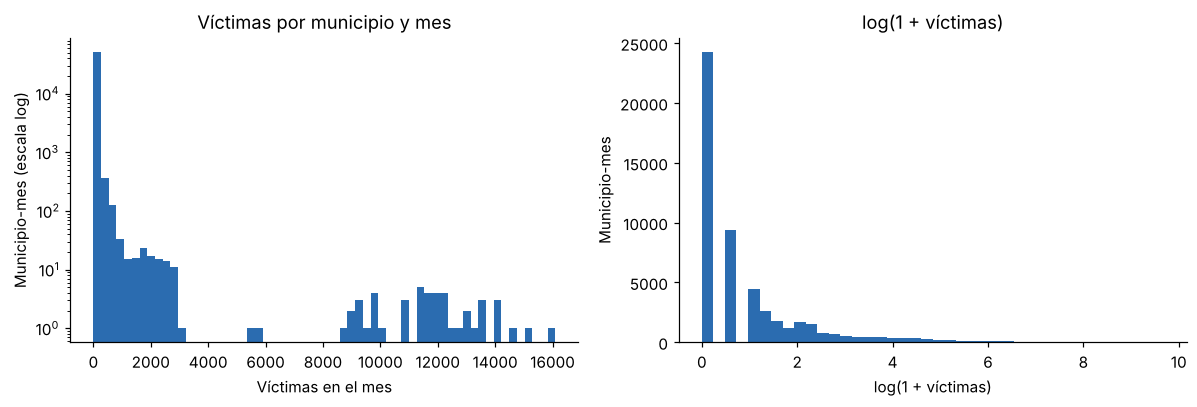

Proporción de municipio-mes con 0 víctimas: 46.1 %
Municipio-mes por encima de 1.000 víctimas: 165


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(df.victimas, bins=60, color='#2b6cb0'); ax[0].set_yscale('log')
ax[0].set_title('Víctimas por municipio y mes'); ax[0].set_xlabel('Víctimas en el mes'); ax[0].set_ylabel('Municipio-mes (escala log)')
ax[1].hist(np.log1p(df.victimas), bins=40, color='#2b6cb0')
ax[1].set_title('log(1 + víctimas)'); ax[1].set_xlabel('log(1 + víctimas)'); ax[1].set_ylabel('Municipio-mes')
plt.tight_layout(); plt.savefig('figuras/01_distribucion_objetivo.png', bbox_inches='tight'); plt.show()
print('Proporción de municipio-mes con 0 víctimas:', round((df.victimas==0).mean()*100,1), '%')
print('Municipio-mes por encima de 1.000 víctimas:', (df.victimas>1000).sum())

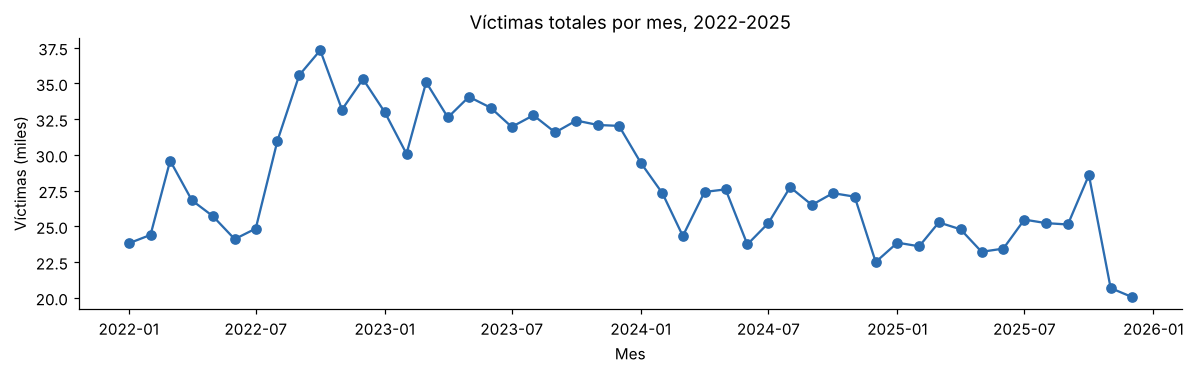

In [5]:
serie = df.groupby('fecha').victimas.sum()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(serie.index, serie.values/1000, marker='o', color='#2b6cb0')
ax.set_title('Víctimas totales por mes, 2022-2025'); ax.set_ylabel('Víctimas (miles)'); ax.set_xlabel('Mes')
plt.tight_layout(); plt.savefig('figuras/02_serie_mensual.png', bbox_inches='tight'); plt.show()

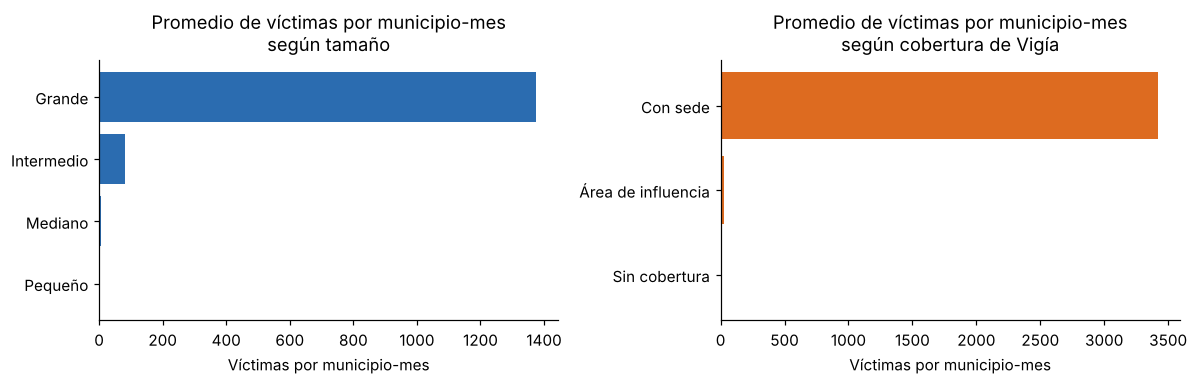

In [6]:
g = df.groupby('categoria_tamano').victimas.mean().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].barh(g.index, g.values, color='#2b6cb0'); ax[0].set_title('Promedio de víctimas por municipio-mes\nsegún tamaño'); ax[0].set_xlabel('Víctimas por municipio-mes')
g2 = df.groupby('estado_cobertura').victimas.mean().sort_values()
ax[1].barh(g2.index, g2.values, color='#dd6b20'); ax[1].set_title('Promedio de víctimas por municipio-mes\nsegún cobertura de Vigía'); ax[1].set_xlabel('Víctimas por municipio-mes')
plt.tight_layout(); plt.savefig('figuras/03_tamano_cobertura.png', bbox_inches='tight'); plt.show()

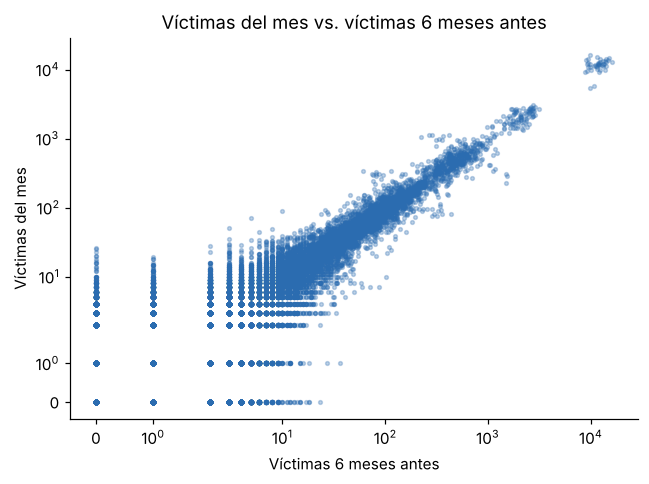

Correlación lag_6 - víctimas: 0.979


In [7]:
d = df.sort_values(['sk_municipio','fecha']).copy()
d['lag_6'] = d.groupby('sk_municipio').victimas.shift(6)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(d.lag_6, d.victimas, s=6, alpha=.3, color='#2b6cb0'); ax.set_xscale('symlog'); ax.set_yscale('symlog')
ax.set_title('Víctimas del mes vs. víctimas 6 meses antes'); ax.set_xlabel('Víctimas 6 meses antes'); ax.set_ylabel('Víctimas del mes')
plt.tight_layout(); plt.savefig('figuras/04_lag6_vs_objetivo.png', bbox_inches='tight'); plt.show()
print('Correlación lag_6 - víctimas:', round(d[['lag_6','victimas']].corr().iloc[0,1], 3))

## 3. Preparación de los datos

In [8]:
d = df.sort_values(['sk_municipio','fecha']).reset_index(drop=True)
# Atípicos: no se eliminan (son ciudades grandes reales); el modelo se entrena sobre log(1+y) para reducir su peso.
q99 = d.victimas.quantile(.99); print('Registros sobre el percentil 99 (se conservan):', (d.victimas>q99).sum())
# Nulos de población (si existieran): mediana del municipio
n_null = d.poblacion_total.isna().sum()
d['poblacion_total'] = d.groupby('sk_municipio').poblacion_total.transform(lambda s: s.fillna(s.median()))
print('Nulos imputados en poblacion_total:', n_null)
g = d.groupby('sk_municipio').victimas
for k in [6, 7, 8, 12]:
    d[f'lag_{k}'] = g.shift(k)
d['media_6_11'] = g.transform(lambda s: s.shift(6).rolling(6).mean())     # promedio de los meses t-11..t-6
d['tasa_lag12_100k'] = d.lag_12 / d.poblacion_total * 1e5                  # tasa del mismo mes del año anterior
d['log_poblacion'] = np.log1p(d.poblacion_total)
d['mes_sin'] = np.sin(2*np.pi*d.mes/12); d['mes_cos'] = np.cos(2*np.pi*d.mes/12)
cat = ['region','categoria_tamano','tipo_ruralidad','estado_cobertura']
X_all = pd.get_dummies(d[cat], drop_first=False, dtype=int)
num = ['lag_6','lag_7','lag_8','lag_12','media_6_11','tasa_lag12_100k','log_poblacion','mes_sin','mes_cos','dias_festivos','dias_fin_semana']
d = pd.concat([d, X_all], axis=1); feats = num + list(X_all.columns)
modelable = d.dropna(subset=num).copy()
print('Filas con lags completos:', len(modelable), '| descartadas por falta de historia (2022):', len(d)-len(modelable))

Registros sobre el percentil 99 (se conservan): 526
Nulos imputados en poblacion_total: 0


Filas con lags completos: 39420 | descartadas por falta de historia (2022): 13140


In [9]:
corte = pd.Timestamp('2025-07-01')
train = modelable[modelable.fecha < corte]; test = modelable[modelable.fecha >= corte]
print('Entrenamiento:', len(train), train.fecha.min().date(), '->', train.fecha.max().date())
print('Prueba:', len(test), test.fecha.min().date(), '->', test.fecha.max().date())
Xtr, Xte = train[feats], test[feats]; ytr, yte = train.victimas, test.victimas

Entrenamiento: 32850 2023-01-01 -> 2025-06-01
Prueba: 6570 2025-07-01 -> 2025-12-01


## 4. Modelado (mismo conjunto de entrenamiento y mismas variables)

In [10]:
modelos = {
    'Regresión lineal': LinearRegression(),
    'Bosque aleatorio': RandomForestRegressor(n_estimators=300, max_depth=14, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
}
pred = {}
for nombre, m in modelos.items():
    m.fit(Xtr, np.log1p(ytr))
    pred[nombre] = np.clip(np.expm1(m.predict(Xte)), 0, None)
pred['Ingenuo (mismo mes año anterior)'] = test.lag_12.values

## 5. Evaluación sobre la prueba (julio-diciembre 2025)

In [11]:
filas = []
for nombre, p in pred.items():
    mae = mean_absolute_error(yte, p); rmse = mean_squared_error(yte, p) ** .5
    filas.append([nombre, round(mae, 2), round(rmse, 2), round(abs(p.sum()-yte.sum())/yte.sum()*100, 2)])
res = pd.DataFrame(filas, columns=['Algoritmo','MAE','RMSE','Error total %']).set_index('Algoritmo')
res.to_csv('figuras/metricas.csv'); res

,MAE,RMSE,Error total %
Algoritmo,,,
Regresión lineal,9.19,137.33,9.77
Bosque aleatorio,5.82,92.38,4.29
Ingenuo (mismo mes año anterior),6.32,102.04,7.73


Modelo elegido: Bosque aleatorio


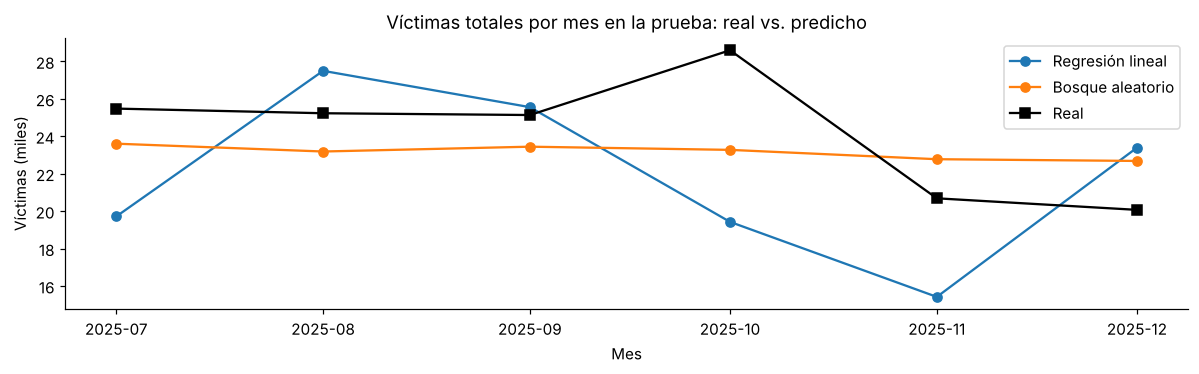

In [12]:
mejor = res.drop(index='Ingenuo (mismo mes año anterior)').MAE.idxmin(); print('Modelo elegido:', mejor)
fig, ax = plt.subplots(figsize=(11, 3.5))
real_m = test.groupby('fecha').victimas.sum()
for nombre in ['Regresión lineal','Bosque aleatorio']:
    ax.plot(real_m.index, pd.Series(pred[nombre], index=test.index).groupby(test.fecha).sum().values/1000, marker='o', label=nombre)
ax.plot(real_m.index, real_m.values/1000, marker='s', color='black', label='Real')
ax.set_title('Víctimas totales por mes en la prueba: real vs. predicho'); ax.set_ylabel('Víctimas (miles)'); ax.set_xlabel('Mes'); ax.legend()
plt.tight_layout(); plt.savefig('figuras/05_real_vs_predicho.png', bbox_inches='tight'); plt.show()

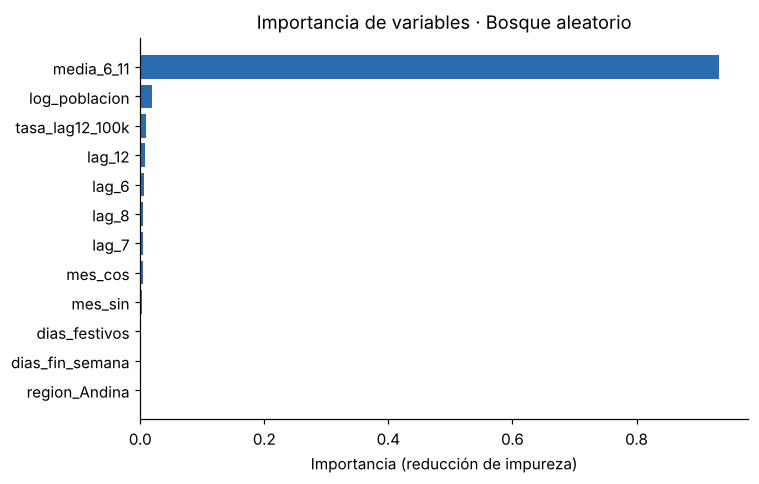

media_6_11         0.933
log_poblacion      0.018
tasa_lag12_100k    0.009
lag_12             0.008
lag_6              0.006
lag_8              0.005
lag_7              0.004
mes_cos            0.004
mes_sin            0.003
dias_festivos      0.002
dias_fin_semana    0.002
region_Andina      0.001
dtype: float64

In [13]:
rf = modelos['Bosque aleatorio']
imp = pd.Series(rf.feature_importances_, index=feats).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7, 4.5)); ax.barh(imp.index, imp.values, color='#2b6cb0')
ax.set_title('Importancia de variables · Bosque aleatorio'); ax.set_xlabel('Importancia (reducción de impureza)')
plt.tight_layout(); plt.savefig('figuras/06_importancia.png', bbox_inches='tight'); plt.show()
imp.sort_values(ascending=False).round(3)

In [14]:
# Error por tamaño de municipio (modelo elegido)
t = test.assign(pred=pred[mejor], err=lambda x: (x.pred-x.victimas).abs())
print(t.groupby('categoria_tamano').agg(municipio_mes=('err','size'), victimas_promedio=('victimas','mean'), MAE=('err','mean')).round(1))
print('MAE de los 10 municipios con más víctimas:', round(t[t.sk_municipio.isin(t.groupby('sk_municipio').victimas.sum().nlargest(10).index)].err.mean(),1))

                  municipio_mes  victimas_promedio    MAE
categoria_tamano                                         
Grande                       90             1187.0  274.0
Intermedio                  378               70.8   18.0
Mediano                    2010                4.4    2.1
Pequeño                    4092                0.7    0.6
MAE de los 10 municipios con más víctimas: 392.0


## 6. Pronóstico de los próximos seis meses (enero-junio 2026) y despliegue

In [15]:
# Se reentrena el modelo elegido con todo el historial disponible y se pronostica ene-jun 2026
final = RandomForestRegressor(**modelos['Bosque aleatorio'].get_params()) if mejor=='Bosque aleatorio' else LinearRegression()
final.fit(modelable[feats], np.log1p(modelable.victimas))
base = d[d.fecha.dt.year==2025].copy()
fut = []
for k in range(1, 7):
    f = base[base.mes==k].copy()                   # mismo municipio, mes k de 2025 -> mes k de 2026
    f['fecha'] = pd.Timestamp(2026, k, 1); f['anio'] = 2026
    hist = d.set_index(['sk_municipio','fecha']).victimas
    for lag in [6,7,8,12]:
        f[f'lag_{lag}'] = [hist.get((m, f.fecha.iloc[0] - pd.DateOffset(months=lag)), np.nan) for m in f.sk_municipio]
    f['media_6_11'] = [np.mean([hist.get((m, f.fecha.iloc[0] - pd.DateOffset(months=j)), np.nan) for j in range(6,12)]) for m in f.sk_municipio]
    f['tasa_lag12_100k'] = f.lag_12 / f.poblacion_total * 1e5
    fut.append(f)
fut = pd.concat(fut)
fut['victimas_predichas'] = np.clip(np.expm1(final.predict(fut[feats])), 0, None)
print('Víctimas esperadas ene-jun 2026:', int(fut.victimas_predichas.sum()), '| mismo semestre 2025 real:', int(d[(d.anio==2025)&(d.mes<=6)].victimas.sum()))
fut.groupby('nombre_municipio').victimas_predichas.sum().nlargest(10).round(0)

Víctimas esperadas ene-jun 2026: 134844 | mismo semestre 2025 real: 144201


nombre_municipio
BOGOTÁ, D.C.           57516.0
MEDELLÍN               12781.0
SANTIAGO DE CALI        9014.0
BARRANQUILLA            4536.0
PASTO                   3176.0
CARTAGENA DE INDIAS     2976.0
SOACHA                  2852.0
BUCARAMANGA             2368.0
IBAGUÉ                  2229.0
VILLAVICENCIO           2203.0
Name: victimas_predichas, dtype: float64

In [16]:
MODELO = mejor
p_test = test[['sk_municipio','anio','mes','sk_tiempo_mes','victimas']].assign(
    victimas_predichas=np.round(pred[mejor], 2), tipo_periodo='Prueba 2025', modelo=MODELO)
p_fut = fut[['sk_municipio','anio','mes']].assign(sk_tiempo_mes=None, victimas=None,
    victimas_predichas=fut.victimas_predichas.round(2).values, tipo_periodo='Pronóstico 2026', modelo=MODELO)
pred_tab = pd.concat([p_test, p_fut]).rename(columns={'sk_tiempo_mes':'sk_tiempo','victimas':'victimas_reales'})
pred_tab['error_absoluto'] = (pred_tab.victimas_predichas - pred_tab.victimas_reales).abs().round(2)
pred_tab['fecha_carga'] = pd.Timestamp.today().normalize()
pred_tab = pred_tab[['sk_municipio','sk_tiempo','anio','mes','tipo_periodo','victimas_reales','victimas_predichas','error_absoluto','modelo','fecha_carga']]
pred_tab.to_csv('predicciones_hurto_municipio_mes.csv', index=False, encoding='utf-8')
# Despliegue en el data warehouse: la tabla se crea con dw/ddl/14_pred_hurto_municipio_mes.sql
with engine.begin() as con:
    con.execute(text(leer('../dw/ddl/14_pred_hurto_municipio_mes.sql', 'dw/ddl/14_pred_hurto_municipio_mes.sql')))
pred_tab.to_sql('pred_hurto_municipio_mes', engine, schema='dw', if_exists='append', index=False, method='multi', chunksize=2000)
print(pd.read_sql('SELECT tipo_periodo, COUNT(*) filas, SUM(victimas_reales) reales, ROUND(SUM(victimas_predichas)) predichas FROM dw.pred_hurto_municipio_mes GROUP BY 1', engine))

      tipo_periodo  filas    reales  predichas
0  Pronóstico 2026   6570       NaN   134844.0
1      Prueba 2025   6570  145173.0   138944.0
